<a href="https://colab.research.google.com/github/packageIncoming/MAT422/blob/main/MAT422_Section_3_4_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Section 3.4: Logistic Regression

**Topics:** Sigmoid/logistic function, Binary classification probabilities, Logistic regression fitting and interpretation

Mert Isik
MAT422
Fall 2026


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)


## Sigmoid/logistic function

This section gives one compact Python demonstration of **Sigmoid/logistic function**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


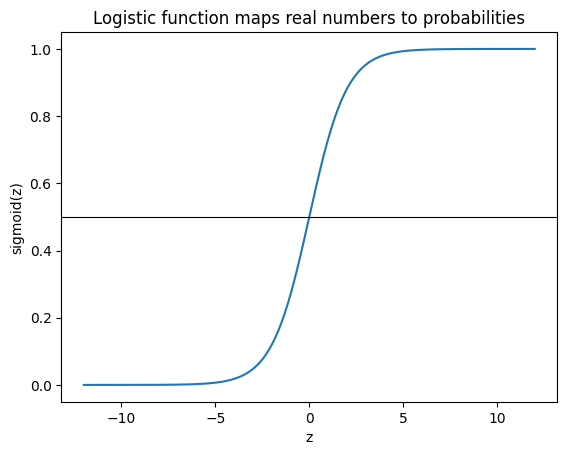

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-12, 12, 300)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="black", linewidth=0.8)
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Logistic function maps real numbers to probabilities")
plt.show()


Sigmoid, explained informally, is a helpful function that maps any number between negative infinity to positive infinite to between 0 and 1. Sigmoid(0) = 0.5 exactly. Larger numbers get closer to 1.0, smaller numbers get closer to 0.0. This is particularly useful for linear regression since it effectively squashes the result into a probability, since probability must be between 0 and 1.

## Binary classification probabilities

This section gives one compact Python demonstration of **Binary classification probabilities**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


In [11]:
X, y = make_classification(n_samples=240, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=1.2, random_state=422)
model = LogisticRegression()
model.fit(X, y)
pred = model.predict(X)
proba = model.predict_proba(X)[:, 1]

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))


Coefficients: [[0.4573 1.7545]]
Intercept: [0.6209]
Training accuracy: 0.875
Confusion matrix:
[[105  15]
 [ 15 105]]


Binary classification is a method to classify an input as either part of a category or not part of a caategory. Given an input, it will generate a confidence output between [0,1] that that input is in the classification. We then pick the cutoff for what determines an input is within the category such as 0.5.

## Logistic regression fitting and interpretation

This section gives one compact Python demonstration of **Logistic regression fitting and interpretation**. After running the code, add your own interpretation and change at least one input, parameter, or example so the notebook reflects your own work.


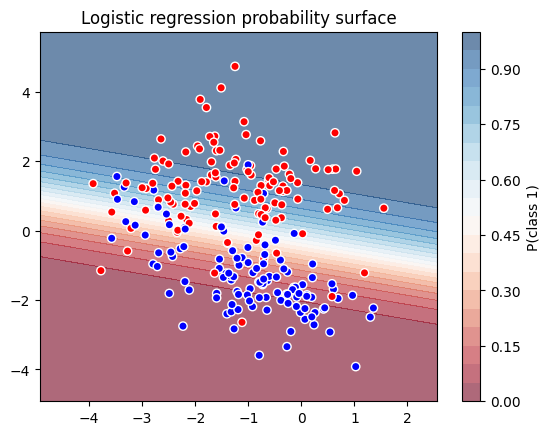

In [18]:
xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 240),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 240))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="P(class 1)")
plt.scatter(X[:,0], X[:,1], c=y, edgecolor="white", cmap="bwr")
plt.title("Logistic regression probability surface")
plt.show()


Fitting informally is the model finding the best line to separate the two categories on its own by guessing and adjusting until adjustments aren't needed. The result is the coefficients [0.4573, 1.7545] and the intercept 0.6209, where the second feature’s weight is roughly 3.8 times larger than the first and therefore carries much more influence over the prediction. The plot shows this as a smooth gradient instead of a hard split and the band where the colors meet is known as the decision boundary.

## Reflection and Submission Checklist

- [X] I explained each concept in words before or after the code.
- [X] I verified important claims numerically or visually.
- [X] I changed or extended at least one example so the notebook reflects my own work.
- [X] I ran the notebook from top to bottom without errors.
- [X] I saved the notebook from Google Colab directly to GitHub, following the course instructions.
